# PQ-IoMT: Base Paper vs Session-Key Variant — Side-by-Side Comparison

This notebook benchmarks both implementations and renders all comparison charts inline.

## Protocol overview

```
BASE PAPER (demo-checkpoint.ipynb)
──────────────────────────────────
Sensor ──── sign only (plaintext) ────► QSES ──── KEM+AES+sign ────► Server
           (2 584 B, readable)                   (5 832 B, encrypted)

SECURE VARIANT (session_link_demo.ipynb)
────────────────────────────────────────
Sensor ──── AES-GCM encrypted ────► QSES ──── KEM+AES+sign ────► Server
           (2 616 B, ciphertext)     (5 832 B, identical)
  ↑
  One ML-KEM handshake per session sets up the shared AES key.
  The QSES→Server hop is unchanged in both variants.
```

| | Base paper | Secure variant |
|---|---|---|
| **Sensor → QSES** | Plaintext (ML-DSA sign + HMAC) | AES-256-GCM encrypted |
| **QSES → Server** | ML-KEM + AES + QSES sign | **Identical** |
| **Session setup** | None | ML-KEM-512 handshake (once per session) |
| **Confidentiality** | ❌ None on 1st hop | ✅ Full on 1st hop |
| **Forward secrecy** | N/A | ✅ ephemeral Kyber key deleted after HS |


In [71]:
import json
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.entities.client import ClientNode
from src.entities.qses import QSESNode
from src.entities.server import MedicalServerNode
from src.entities.secure_client import SecureClientNode
from src.entities.secure_qses import SecureQSESNode
from src.protocol.messages import CLIENT_PACKET_SIZE, EDGE_PACKET_SIZE
from src.protocol.secure_messages import LINK_PACKET_SIZE, NONCE_SIZE

# ── colour palette ───────────────────────────────────────────────────────
C_BASE   = "#064D80"
C_SECURE = "#F60C0C"
C_ACCENT = "#DE8D0A"
C_GREEN  = "#269118"
DARK_BG  = "#F7F7FA"
CARD_BG  = "#CFD2D2"
GRID_CLR = "#BA5BEA"
TEXT_CLR = "#050404"

plt.rcParams.update({
    'figure.facecolor': DARK_BG, 'axes.facecolor': CARD_BG,
    'axes.edgecolor': GRID_CLR,  'axes.labelcolor': TEXT_CLR,
    'xtick.color': TEXT_CLR,     'ytick.color': TEXT_CLR,
    'text.color': TEXT_CLR,      'grid.color': GRID_CLR,
    'grid.linestyle': '--',      'grid.linewidth': 0.5,
    'legend.facecolor': CARD_BG, 'legend.edgecolor': GRID_CLR,
    'legend.labelcolor': TEXT_CLR, 'font.family': 'DejaVu Sans',
})

TELEMETRY     = b'Heart rate: 78'
WARMUP        = 15
N_ITER        = 200
SESSION_SIZES = [1, 2, 5, 10, 20, 50, 100, 200, 500]

def summarize(samples):
    s = sorted(samples); n = len(s)
    return dict(mean=statistics.mean(s), median=statistics.median(s),
                stdev=statistics.stdev(s) if n > 1 else 0.0,
                p95=s[int(0.95*(n-1))], p5=s[int(0.05*(n-1))],
                min=s[0], max=s[-1])

print(f'Project root : {ROOT}')
print(f'Iterations   : {N_ITER} measured (+{WARMUP} warmup)')


Project root : /Users/prashant/pq-iomt-framework
Iterations   : 200 measured (+15 warmup)


## Step 1 — Build both systems

We create identical server, QSES and sensor nodes for both variants so the only difference is the Sensor→QSES link.

In [72]:
def make_base_system():
    server = MedicalServerNode(server_id=9)
    client = ClientNode(client_id=1, server_id=9, session_id=3, qses_nonce=222)
    qses   = QSESNode(server.public_key, max_age_ms=10*60*1000)
    qses.register_client(1, client.public_key)
    server.trust_qses(qses.public_key)
    server.register_client(1, client.public_key, client.hmac_key, 222)
    return server, qses, client


def make_secure_system():
    server = MedicalServerNode(server_id=9)
    qses   = SecureQSESNode(server.public_key, max_age_ms=10*60*1000)
    client = SecureClientNode(client_id=1, server_id=9, session_id=3,
                              qses_nonce=222, qses_public_key=qses.public_key)
    qses.register_client(1, client.public_key)
    server.trust_qses(qses.public_key)
    server.register_client(1, client.public_key, client.hmac_key, 222)
    return server, qses, client


def do_handshake(q, c):
    """ML-KEM handshake — runs ONCE per session on the Sensor<->QSES link."""
    cid, n_i, pk_kem, sig_d = c.begin_session()
    n_q, sid, ct, sig_q     = q.accept_session(cid, n_i, pk_kem, sig_d)
    c.complete_session(n_q, sid, ct, sig_q)
    return sid


print('System factories defined.')
print('Note: The QSES has sequence-number replay protection, so we')
print('pre-generate all packets, then measure each stage individually.')


System factories defined.
Note: The QSES has sequence-number replay protection, so we
pre-generate all packets, then measure each stage individually.


## Step 2 — Benchmark: Base Paper Pipeline

**Algorithm flow (per reading):**
1. Device: pad message → build metadata → SHA3-256 → ML-DSA-44 sign → HMAC
2. QSES: verify seq+timestamp, verify ML-DSA sig → ML-KEM Encaps → HKDF → AES-GCM → ML-DSA sign
3. Server: verify QSES sig → ML-KEM Decaps → AES-GCM decrypt → verify device sig + HMAC

The Sensor → QSES packet is **plaintext** — anyone on that link can read it.


In [73]:
total = N_ITER + WARMUP

print(f'Base paper pipeline: {total} packets ({WARMUP} warmup + {N_ITER} measured)')
server_b, qses_b, client_b = make_base_system()

# Stage 1: Device
device_times_b, client_pkts = [], []
for i in range(total):
    t0 = time.perf_counter()
    pkt = client_b.create_signed_reading(TELEMETRY)
    dt  = (time.perf_counter() - t0) * 1000
    client_pkts.append(pkt)
    if i >= WARMUP: device_times_b.append(dt)

# Stage 2: QSES
qses_times_b, edge_pkts = [], []
for i, pkt in enumerate(client_pkts):
    t0 = time.perf_counter()
    ep = qses_b.process_and_forward(pkt)
    dt = (time.perf_counter() - t0) * 1000
    edge_pkts.append(ep)
    if i >= WARMUP: qses_times_b.append(dt)

# Stage 3: Server
server_times_b = []
for i, ep in enumerate(edge_pkts):
    t0 = time.perf_counter()
    server_b.receive_and_verify(ep)
    dt = (time.perf_counter() - t0) * 1000
    if i >= WARMUP: server_times_b.append(dt)

base_device = summarize(device_times_b)
base_qses   = summarize(qses_times_b)
base_server = summarize(server_times_b)

print(f"\n{'Entity':<18} {'mean':>9} {'median':>9} {'p95':>9} {'stdev':>9}  (ms)")
print('-'*58)
for label, s in [('Device (sign)', base_device), ('QSES (fwd)', base_qses), ('Server (verify)', base_server)]:
    print(f"{label:<18} {s['mean']:>9.4f} {s['median']:>9.4f} {s['p95']:>9.4f} {s['stdev']:>9.4f}")
print(f"\nSensor->QSES packet : {CLIENT_PACKET_SIZE:,} bytes")
print(f"QSES->Server packet : {EDGE_PACKET_SIZE:,} bytes")


Base paper pipeline: 215 packets (15 warmup + 200 measured)

Entity                  mean    median       p95     stdev  (ms)
----------------------------------------------------------
Device (sign)         0.1417    0.0912    0.3784    0.2435
QSES (fwd)            0.1568    0.1425    0.2508    0.0522
Server (verify)       0.1084    0.1000    0.1659    0.0286

Sensor->QSES packet : 2,584 bytes
QSES->Server packet : 5,832 bytes


## Step 3 — Benchmark: Secure Session-Key Pipeline

**Additional setup (ONCE per session):**
- Sensor makes a fresh ML-KEM-512 key pair, signs the public half (ML-DSA)
- QSES verifies, runs Encaps → derives AES session key K, signs reply
- Sensor verifies, runs Decaps → same K, **deletes sk_kem** (forward secrecy)

**Per reading:** same ML-DSA sign as before, then AES-256-GCM encrypt with K.  
**The QSES→Server hop is completely unchanged.**


In [74]:
print(f'Secure pipeline: {total} packets ({WARMUP} warmup + {N_ITER} measured)')
server_s, qses_s, client_s = make_secure_system()

# Handshake: ML-KEM runs ONCE per session
t_hs0 = time.perf_counter()
sid = do_handshake(qses_s, client_s)
hs_setup_ms = (time.perf_counter() - t_hs0) * 1000
print(f'  Handshake done (session_id={sid}) in {hs_setup_ms:.3f} ms')
print(f'  -> ML-KEM Encaps (at QSES) + Decaps (at Sensor) ran ONCE')
print(f'  -> AES session key K established; sk_kem deleted')
print()

# Stage 1: Device
device_times_s, link_pkts = [], []
for i in range(total):
    t0 = time.perf_counter()
    lp = client_s.create_encrypted_reading(TELEMETRY)  # sign + AES-GCM only
    dt = (time.perf_counter() - t0) * 1000
    link_pkts.append(lp)
    if i >= WARMUP: device_times_s.append(dt)

# Stage 2: QSES
qses_times_s, edge_pkts_s = [], []
for i, lp in enumerate(link_pkts):
    t0 = time.perf_counter()
    ep = qses_s.receive_from_sensor(lp)   # AES-GCM decrypt + fwd (no KEM)
    dt = (time.perf_counter() - t0) * 1000
    edge_pkts_s.append(ep)
    if i >= WARMUP: qses_times_s.append(dt)

# Stage 3: Server (identical to base)
server_times_s = []
for i, ep in enumerate(edge_pkts_s):
    t0 = time.perf_counter()
    server_s.receive_and_verify(ep)
    dt = (time.perf_counter() - t0) * 1000
    if i >= WARMUP: server_times_s.append(dt)

secure_device = summarize(device_times_s)
secure_qses   = summarize(qses_times_s)
secure_server = summarize(server_times_s)

print(f"{'Entity':<22} {'mean':>9} {'median':>9} {'p95':>9} {'stdev':>9}  (ms)")
print('-'*62)
for label, s in [('Device (sign+AES-GCM)', secure_device),
                 ('QSES (AES-GCM+fwd)',   secure_qses),
                 ('Server (verify)',       secure_server)]:
    print(f"{label:<22} {s['mean']:>9.4f} {s['median']:>9.4f} {s['p95']:>9.4f} {s['stdev']:>9.4f}")
print(f"\nSensor->QSES packet : {LINK_PACKET_SIZE:,} bytes (encrypted)")
print(f"QSES->Server packet : {EDGE_PACKET_SIZE:,} bytes (unchanged)")


Secure pipeline: 215 packets (15 warmup + 200 measured)
  Handshake done (session_id=3378445600) in 1.090 ms
  -> ML-KEM Encaps (at QSES) + Decaps (at Sensor) ran ONCE
  -> AES session key K established; sk_kem deleted

Entity                      mean    median       p95     stdev  (ms)
--------------------------------------------------------------
Device (sign+AES-GCM)     0.0943    0.0752    0.1845    0.0613
QSES (AES-GCM+fwd)        0.1618    0.1493    0.2537    0.0510
Server (verify)           0.1068    0.1019    0.1405    0.0145

Sensor->QSES packet : 2,616 bytes (encrypted)
QSES->Server packet : 5,832 bytes (unchanged)


## Step 4 — Handshake Cost (isolated)

We measure the full 3-step ML-KEM handshake in isolation so we can accurately amortise it.

| Step | Who | Operation |
|---|---|---|
| 1 | Sensor → QSES | ML-DSA sign(n_i \| pk_kem) — 3 240 B |
| 2 | QSES → Sensor | ML-KEM Encaps + ML-DSA sign(ct \| n_q) — 3 208 B |
| 3 | Sensor | ML-KEM Decaps → K, delete sk_kem |


In [75]:
hs_samples = []
HS_N = 60 + WARMUP
for i in range(HS_N):
    sv = MedicalServerNode(server_id=9)
    qs = SecureQSESNode(sv.public_key, max_age_ms=10*60*1000)
    cl = SecureClientNode(client_id=1, server_id=9, session_id=3,
                          qses_nonce=222, qses_public_key=qs.public_key)
    qs.register_client(1, cl.public_key)
    t0 = time.perf_counter()
    cid, n_i, pk_kem, sig_d = cl.begin_session()
    n_q, sid, ct, sig_q     = qs.accept_session(cid, n_i, pk_kem, sig_d)
    cl.complete_session(n_q, sid, ct, sig_q)
    dt = (time.perf_counter() - t0) * 1000
    if i >= WARMUP: hs_samples.append(dt)

hs_stats = summarize(hs_samples)

nonce_sz    = NONCE_SIZE        # 16
hello_bytes = 4 + nonce_sz + 800 + 2420   # 3240
reply_bytes = nonce_sz + 4 + 768 + 2420   # 3208
hs_bytes    = hello_bytes + reply_bytes    # 6448

print(f"Handshake timing ({len(hs_samples)} samples):")
print(f"  mean   : {hs_stats['mean']:.4f} ms")
print(f"  median : {hs_stats['median']:.4f} ms")
print(f"  p95    : {hs_stats['p95']:.4f} ms")
print(f"  stdev  : {hs_stats['stdev']:.4f} ms")
print()
print(f"Handshake wire cost:")
print(f"  Sensor -> QSES (hello) : {hello_bytes:,} B")
print(f"  QSES -> Sensor (reply) : {reply_bytes:,} B")
print(f"  Total                  : {hs_bytes:,} B")


Handshake timing (60 samples):
  mean   : 0.2964 ms
  median : 0.2734 ms
  p95    : 0.4426 ms
  stdev  : 0.0705 ms

Handshake wire cost:
  Sensor -> QSES (hello) : 3,240 B
  QSES -> Sensor (reply) : 3,208 B
  Total                  : 6,448 B


## Step 5 — Derived Overhead Numbers

In [76]:
delta_device_ms = secure_device['mean'] - base_device['mean']
delta_qses_ms   = secure_qses['mean']   - base_qses['mean']
handshake_ms    = hs_stats['mean']

base_link_size   = CLIENT_PACKET_SIZE   # 2584
secure_link_size = LINK_PACKET_SIZE     # 2616
link_overhead    = secure_link_size - base_link_size   # 32
edge_size        = EDGE_PACKET_SIZE                    # 5832

amortized = [(handshake_ms/n + delta_device_ms + delta_qses_ms) for n in SESSION_SIZES]

print('Per-reading deltas (Secure - Base):')
print(f'  Device  : {delta_device_ms:+.4f} ms ({delta_device_ms/base_device["mean"]*100:+.1f}%)')
print(f'  QSES    : {delta_qses_ms:+.4f} ms ({delta_qses_ms/base_qses["mean"]*100:+.1f}%)')
print(f'  Server  : {secure_server["mean"]-base_server["mean"]:+.4f} ms (unchanged hop)')
print()
print('Packet size delta (Sensor->QSES per reading):')
print(f'  +{link_overhead} B ({link_overhead/base_link_size*100:.1f}% overhead)')
print()
print('Byte break-even (when HS cost is amortised by per-pkt overhead):')
be = hs_bytes // link_overhead
print(f'  @ ~{be} packets per session')
print()
print('Amortized overhead per reading (Device+QSES) for various session sizes:')
print(f"  {'N packets':>10}  {'overhead/reading':>18}  {'% overhead':>12}")
base_sum = base_device['mean'] + base_qses['mean']
for n, ov in zip(SESSION_SIZES, amortized):
    print(f'  {n:>10}  {ov:>16.4f} ms  {ov/base_sum*100:>10.1f}%')


Per-reading deltas (Secure - Base):
  Device  : -0.0473 ms (-33.4%)
  QSES    : +0.0050 ms (+3.2%)
  Server  : -0.0015 ms (unchanged hop)

Packet size delta (Sensor->QSES per reading):
  +32 B (1.2% overhead)

Byte break-even (when HS cost is amortised by per-pkt overhead):
  @ ~201 packets per session

Amortized overhead per reading (Device+QSES) for various session sizes:
   N packets    overhead/reading    % overhead
           1            0.2540 ms        85.1%
           2            0.1058 ms        35.5%
           5            0.0169 ms         5.7%
          10           -0.0127 ms        -4.3%
          20           -0.0276 ms        -9.2%
          50           -0.0364 ms       -12.2%
         100           -0.0394 ms       -13.2%
         200           -0.0409 ms       -13.7%
         500           -0.0418 ms       -14.0%


## Chart 1 — Per-Reading Latency: Base vs Secure

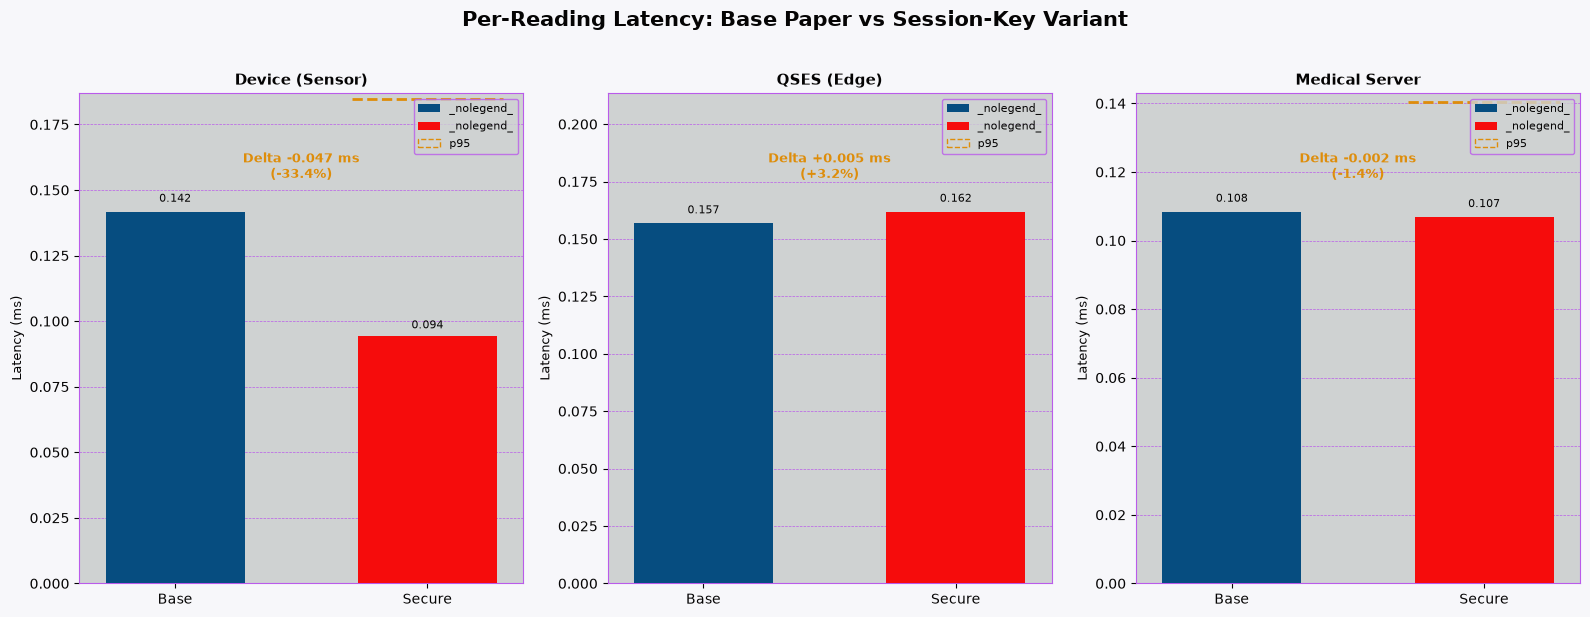

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Per-Reading Latency: Base Paper vs Session-Key Variant',
             fontsize=15, fontweight='bold', color=TEXT_CLR, y=1.02)

roles = ['Device (Sensor)', 'QSES (Edge)', 'Medical Server']
bmeans = [base_device['mean'],   base_qses['mean'],   base_server['mean']]
bp95s  = [base_device['p95'],    base_qses['p95'],    base_server['p95']]
smeans = [secure_device['mean'], secure_qses['mean'], secure_server['mean']]
sp95s  = [secure_device['p95'],  secure_qses['p95'],  secure_server['p95']]

for ax, role, bm, bp, sm, sp in zip(axes, roles, bmeans, bp95s, smeans, sp95s):
    w = 0.55
    bb = ax.bar([0], [bm], w, color=C_BASE,   label='Base (plaintext)', zorder=3)
    bs = ax.bar([1], [sm], w, color=C_SECURE, label='Secure (AES-GCM)', zorder=3)
    ax.hlines(bp, -0.3, 0.3, colors=C_ACCENT, linewidths=2, linestyles='--', zorder=4)
    ax.hlines(sp,  0.7, 1.3, colors=C_ACCENT, linewidths=2, linestyles='--', zorder=4)
    pct = (sm/bm - 1)*100 if bm > 0 else 0
    ax.text(0.5, max(bm, sm)*1.08, f'Delta {sm-bm:+.3f} ms\n({pct:+.1f}%)',
            ha='center', va='bottom', fontsize=9, color=C_ACCENT, fontweight='bold')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Base', 'Secure'], fontsize=10)
    ax.set_ylabel('Latency (ms)', fontsize=9)
    ax.set_title(role, fontsize=11, fontweight='bold', color=TEXT_CLR)
    ax.grid(axis='y', zorder=0); ax.set_ylim(0, max(bm, sm)*1.32)
    for bar, v in [(bb[0], bm), (bs[0], sm)]:
        ax.text(bar.get_x()+bar.get_width()/2, v+v*0.02, f'{v:.3f}',
                ha='center', va='bottom', fontsize=8, color=TEXT_CLR)
    pp = mpatches.Patch(color=C_ACCENT, linestyle='--', label='p95', fill=False)
    ax.legend(handles=[bb[0], bs[0], pp], fontsize=8)

plt.tight_layout()
plt.show()


## Chart 2 — Amortized Overhead Per Reading vs Session Length

As sessions get longer, the one-off handshake cost shrinks per reading until only the AES-GCM floor remains.

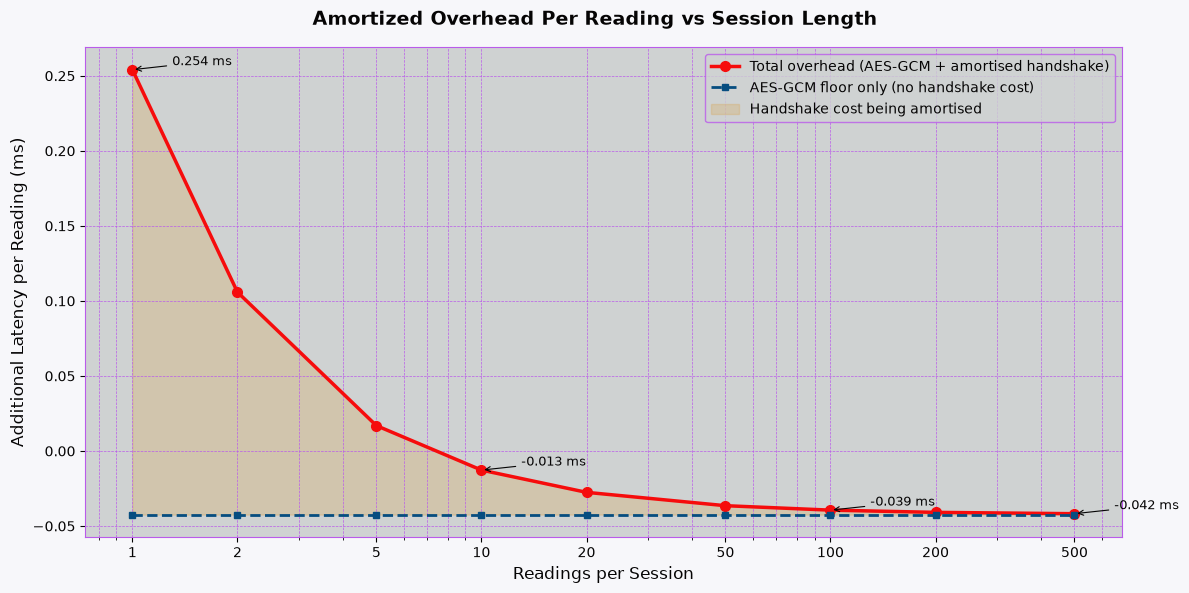

In [78]:
fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle('Amortized Overhead Per Reading vs Session Length',
             fontsize=14, fontweight='bold', color=TEXT_CLR)

floor = [delta_device_ms + delta_qses_ms] * len(SESSION_SIZES)

ax.plot(SESSION_SIZES, amortized, 'o-',  color=C_SECURE, lw=2.5, ms=7,
        label='Total overhead (AES-GCM + amortised handshake)')
ax.plot(SESSION_SIZES, floor,     's--', color=C_BASE,   lw=2,   ms=5,
        label='AES-GCM floor only (no handshake cost)')
ax.fill_between(SESSION_SIZES, floor, amortized, alpha=0.18,
                color=C_ACCENT, label='Handshake cost being amortised')

ax.set_xscale('log'); ax.set_xticks(SESSION_SIZES)
ax.set_xticklabels([str(x) for x in SESSION_SIZES])
ax.set_xlabel('Readings per Session', fontsize=12)
ax.set_ylabel('Additional Latency per Reading (ms)', fontsize=12)
ax.legend(fontsize=10); ax.grid(True, which='both')

for n, ov in zip(SESSION_SIZES, amortized):
    if n in (1, 10, 100, 500):
        ax.annotate(f'{ov:.3f} ms', xy=(n, ov), xytext=(n*1.3, ov+0.003),
                    fontsize=9, color=TEXT_CLR,
                    arrowprops=dict(arrowstyle='->', color=TEXT_CLR, lw=0.8))

plt.tight_layout(); plt.show()


## Chart 3 — Packet Size Breakdown

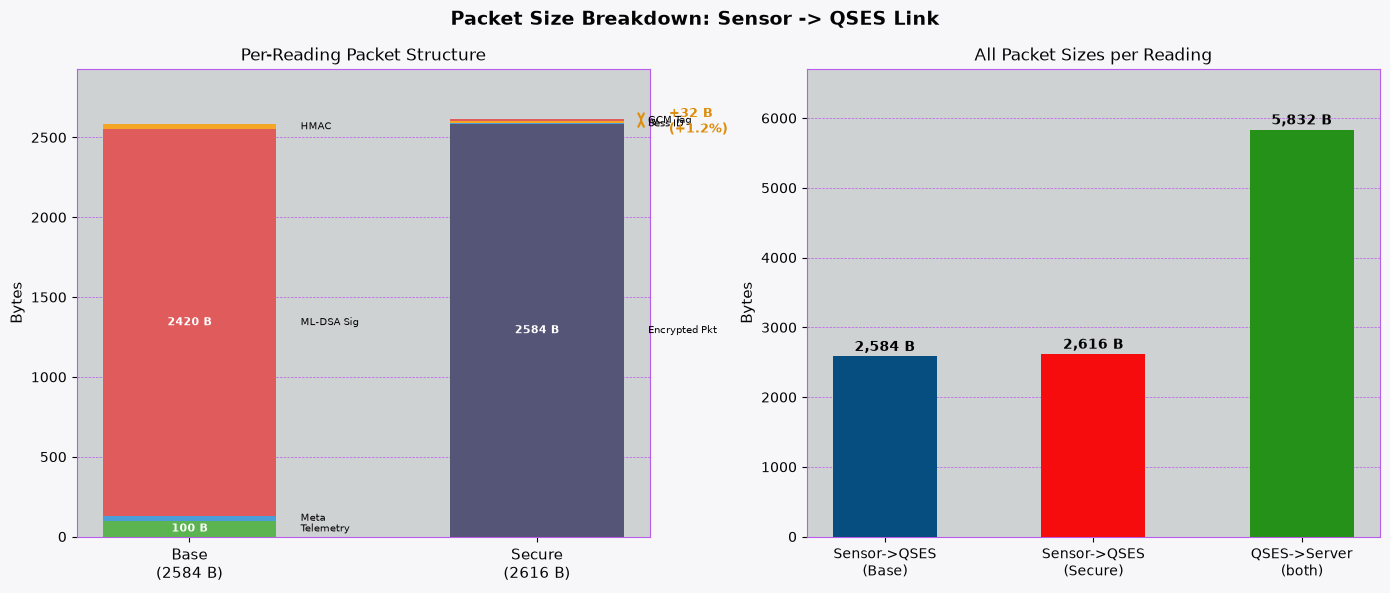

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Packet Size Breakdown: Sensor -> QSES Link',
             fontsize=14, fontweight='bold', color=TEXT_CLR)

ax = axes[0]
bparts = [100, 32, 2420, 32]
sparts = [2584, 4, 12, 16]
bcols  = ['#5BB450','#4C9ED9','#E05C5C','#F5A623']
scols  = ['#555577','#4C9ED9','#F5A623','#E05C5C']
bb, sb = 0, 0
for v, c in zip(bparts, bcols):
    ax.bar(0, v, 0.5, bottom=bb, color=c, zorder=3)
    if v > 50: ax.text(0, bb+v/2, f'{v} B', ha='center', va='center',
                       fontsize=8, color='white', fontweight='bold')
    bb += v
for v, c in zip(sparts, scols):
    ax.bar(1, v, 0.5, bottom=sb, color=c, zorder=3)
    if v > 50: ax.text(1, sb+v/2, f'{v} B', ha='center', va='center',
                       fontsize=8, color='white', fontweight='bold')
    sb += v
for v, lbl, x, dy in [(100,'Telemetry',0,0),(32,'Meta',0,100),
                        (2420,'ML-DSA Sig',0,132),(32,'HMAC',0,2552),
                        (2584,'Encrypted Pkt',1,0),(4,'Sess ID',1,2584),
                        (12,'IV',1,2588),(16,'GCM Tag',1,2600)]:
    ax.text(x+0.32, dy+v/2, lbl, va='center', fontsize=7.5, color=TEXT_CLR)

ax.set_xticks([0,1])
ax.set_xticklabels([f'Base\n({base_link_size} B)', f'Secure\n({secure_link_size} B)'], fontsize=11)
ax.set_ylabel('Bytes', fontsize=11)
ax.set_title('Per-Reading Packet Structure', fontsize=12, color=TEXT_CLR)
ax.grid(axis='y', zorder=0); ax.set_ylim(0, max(base_link_size, secure_link_size)*1.12)
ax.annotate('', xy=(1.3, secure_link_size), xytext=(1.3, base_link_size),
            arrowprops=dict(arrowstyle='<->', color=C_ACCENT, lw=1.5))
ax.text(1.38, (base_link_size+secure_link_size)/2,
        f'+{link_overhead} B\n(+{link_overhead/base_link_size*100:.1f}%)',
        va='center', fontsize=9, color=C_ACCENT, fontweight='bold')

ax2 = axes[1]
labels2 = ['Sensor->QSES\n(Base)','Sensor->QSES\n(Secure)','QSES->Server\n(both)']
sizes2  = [base_link_size, secure_link_size, edge_size]
bars2   = ax2.bar(labels2, sizes2, color=[C_BASE, C_SECURE, C_GREEN], width=0.5, zorder=3)
for bar, sz in zip(bars2, sizes2):
    ax2.text(bar.get_x()+bar.get_width()/2, sz+30, f'{sz:,} B',
             ha='center', va='bottom', fontsize=10, color=TEXT_CLR, fontweight='bold')
ax2.set_ylabel('Bytes', fontsize=11)
ax2.set_title('All Packet Sizes per Reading', fontsize=12, color=TEXT_CLR)
ax2.grid(axis='y', zorder=0); ax2.set_ylim(0, edge_size*1.15)

plt.tight_layout(); plt.show()


## Chart 4 — Per-Operation Breakdown (from `benchmarks/results.json`)

These are the micro-benchmarks already computed by `benchmarks/benchmark.py` for the **base paper** operations.

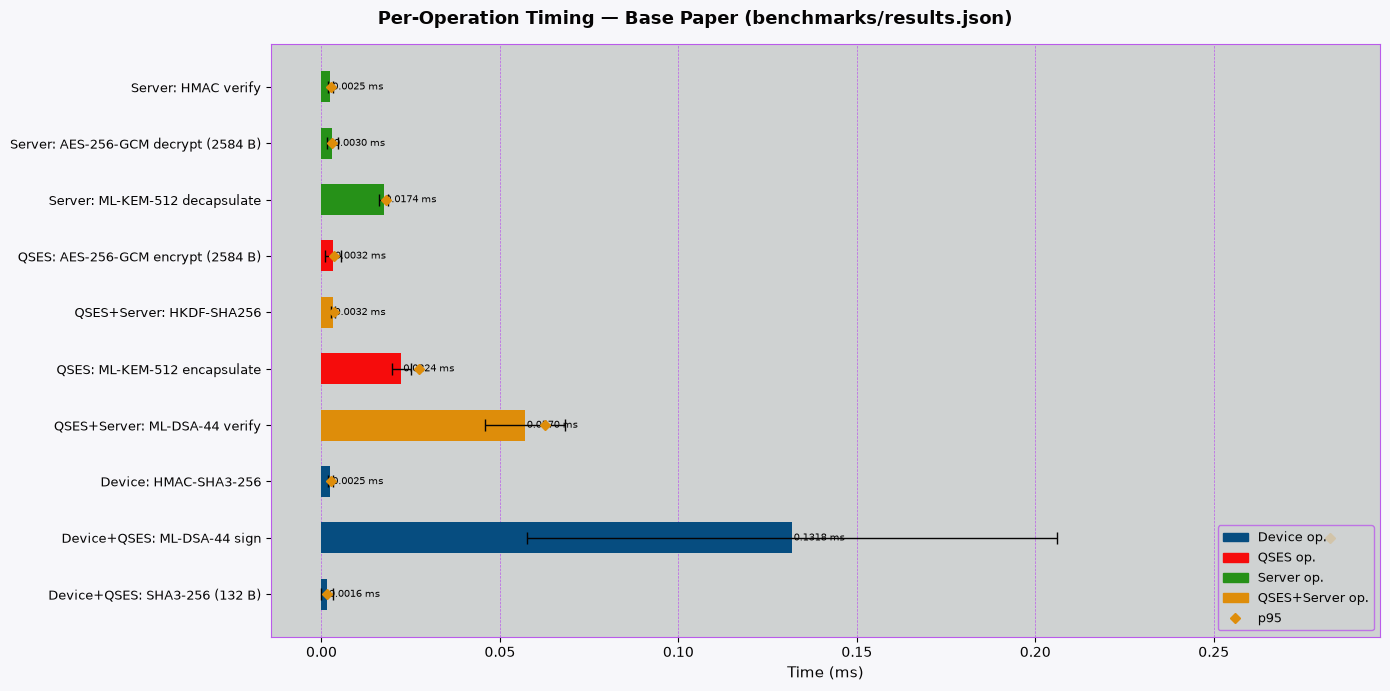

In [80]:
with open(ROOT / 'benchmarks' / 'results.json') as f:
    paper = json.load(f)
ops_data = paper['operations']

fig, ax = plt.subplots(figsize=(14, 7))
fig.suptitle('Per-Operation Timing — Base Paper (benchmarks/results.json)',
             fontsize=13, fontweight='bold', color=TEXT_CLR)

op_names  = list(ops_data.keys())
op_means  = [ops_data[k]['mean']  for k in op_names]
op_p95s   = [ops_data[k]['p95']   for k in op_names]
op_stdevs = [ops_data[k]['stdev'] for k in op_names]

def op_color(n):
    if 'Device' in n:      return C_BASE
    if 'QSES+Server' in n: return C_ACCENT
    if 'QSES' in n:        return C_SECURE
    if 'Server' in n:      return C_GREEN
    return '#AAAAAA'

y = np.arange(len(op_names))
bars = ax.barh(y, op_means, color=[op_color(n) for n in op_names], height=0.55, zorder=3)
ax.errorbar(op_means, y, xerr=op_stdevs, fmt='none',
            ecolor=TEXT_CLR, elinewidth=1, capsize=4, zorder=4)
for i, p in enumerate(op_p95s):
    ax.plot(p, i, 'D', color=C_ACCENT, markersize=5, zorder=5)
ax.set_yticks(y); ax.set_yticklabels(op_names, fontsize=9)
ax.set_xlabel('Time (ms)', fontsize=11); ax.grid(axis='x', zorder=0)
lh = [mpatches.Patch(color=C_BASE,  label='Device op.'),
      mpatches.Patch(color=C_SECURE, label='QSES op.'),
      mpatches.Patch(color=C_GREEN,  label='Server op.'),
      mpatches.Patch(color=C_ACCENT, label='QSES+Server op.'),
      plt.Line2D([0],[0], marker='D', color=C_ACCENT, linestyle='None', ms=5, label='p95')]
ax.legend(handles=lh, fontsize=9, loc='lower right')
for bar, v in zip(bars, op_means):
    ax.text(v+0.0005, bar.get_y()+bar.get_height()/2,
            f'{v:.4f} ms', va='center', fontsize=7.5, color=TEXT_CLR)

plt.tight_layout(); plt.show()


## Chart 5 — Cumulative Overhead as Packet Count Grows (1 – 500)

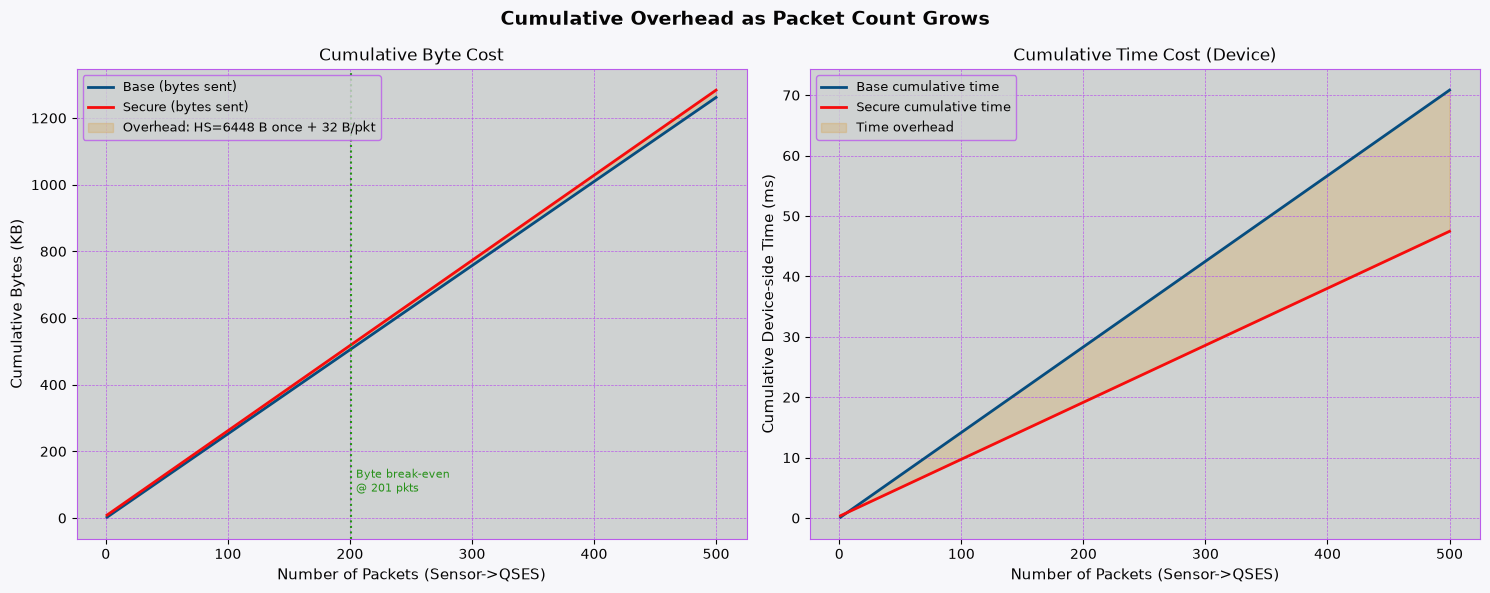

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Cumulative Overhead as Packet Count Grows',
             fontsize=14, fontweight='bold', color=TEXT_CLR)

pr = np.arange(1, 501)
bby = pr * base_link_size
sby = pr * secure_link_size + hs_bytes

ax = axes[0]
ax.plot(pr, bby/1024, color=C_BASE,   lw=2, label='Base (bytes sent)')
ax.plot(pr, sby/1024, color=C_SECURE, lw=2, label='Secure (bytes sent)')
ax.fill_between(pr, bby/1024, sby/1024, alpha=0.2, color=C_ACCENT,
                label=f'Overhead: HS={hs_bytes} B once + {link_overhead} B/pkt')
be = hs_bytes // link_overhead
ax.axvline(x=be, color=C_GREEN, ls=':', lw=1.5)
ylims = ax.get_ylim()
ax.text(be+4, ylims[0]+(ylims[1]-ylims[0])*0.1,
        f'Byte break-even\n@ {be} pkts', fontsize=8, color=C_GREEN)
ax.set_xlabel('Number of Packets (Sensor->QSES)', fontsize=11)
ax.set_ylabel('Cumulative Bytes (KB)', fontsize=11)
ax.set_title('Cumulative Byte Cost', fontsize=12, color=TEXT_CLR)
ax.legend(fontsize=9); ax.grid(True)

bty = pr * base_device['mean']
sty = pr * secure_device['mean'] + hs_stats['mean']
ax2 = axes[1]
ax2.plot(pr, bty, color=C_BASE,   lw=2, label='Base cumulative time')
ax2.plot(pr, sty, color=C_SECURE, lw=2, label='Secure cumulative time')
ax2.fill_between(pr, bty, sty, alpha=0.2, color=C_ACCENT, label='Time overhead')
ax2.set_xlabel('Number of Packets (Sensor->QSES)', fontsize=11)
ax2.set_ylabel('Cumulative Device-side Time (ms)', fontsize=11)
ax2.set_title('Cumulative Time Cost (Device)', fontsize=12, color=TEXT_CLR)
ax2.legend(fontsize=9); ax2.grid(True)
plt.tight_layout(); plt.show()


## Chart 6 — Overhead % vs Session Size

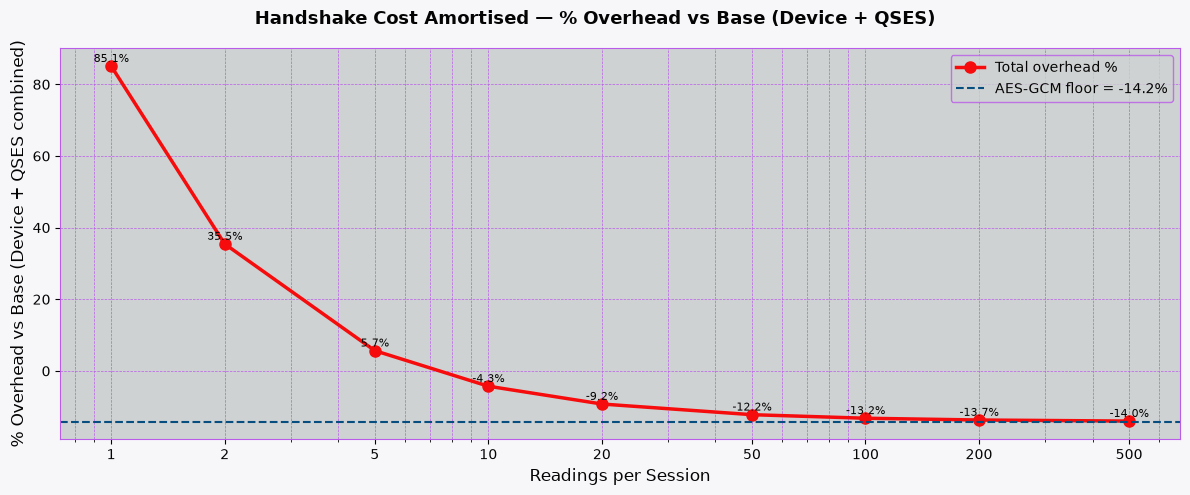

In [82]:
fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle('Handshake Cost Amortised — % Overhead vs Base (Device + QSES)',
             fontsize=13, fontweight='bold', color=TEXT_CLR)

base_sum  = base_device['mean'] + base_qses['mean']
pct_ov    = [(handshake_ms/n + delta_device_ms + delta_qses_ms)/base_sum*100
             for n in SESSION_SIZES]
floor_pct = (delta_device_ms + delta_qses_ms) / base_sum * 100

ax.plot(SESSION_SIZES, pct_ov, 'o-', color=C_SECURE, lw=2.5, ms=8,
        label='Total overhead %')
ax.axhline(y=floor_pct, color=C_BASE, ls='--', lw=1.5,
           label=f'AES-GCM floor = {floor_pct:.1f}%')
for n, p in zip(SESSION_SIZES, pct_ov):
    ax.text(n, p+0.4, f'{p:.1f}%', ha='center', va='bottom',
            fontsize=8, color=TEXT_CLR)
ax.set_xscale('log'); ax.set_xticks(SESSION_SIZES)
ax.set_xticklabels([str(x) for x in SESSION_SIZES])
ax.set_xlabel('Readings per Session', fontsize=12)
ax.set_ylabel('% Overhead vs Base (Device + QSES combined)', fontsize=12)
ax.legend(fontsize=10); ax.grid(True, which='both')
plt.tight_layout(); plt.show()


## Chart 7 — Summary Table

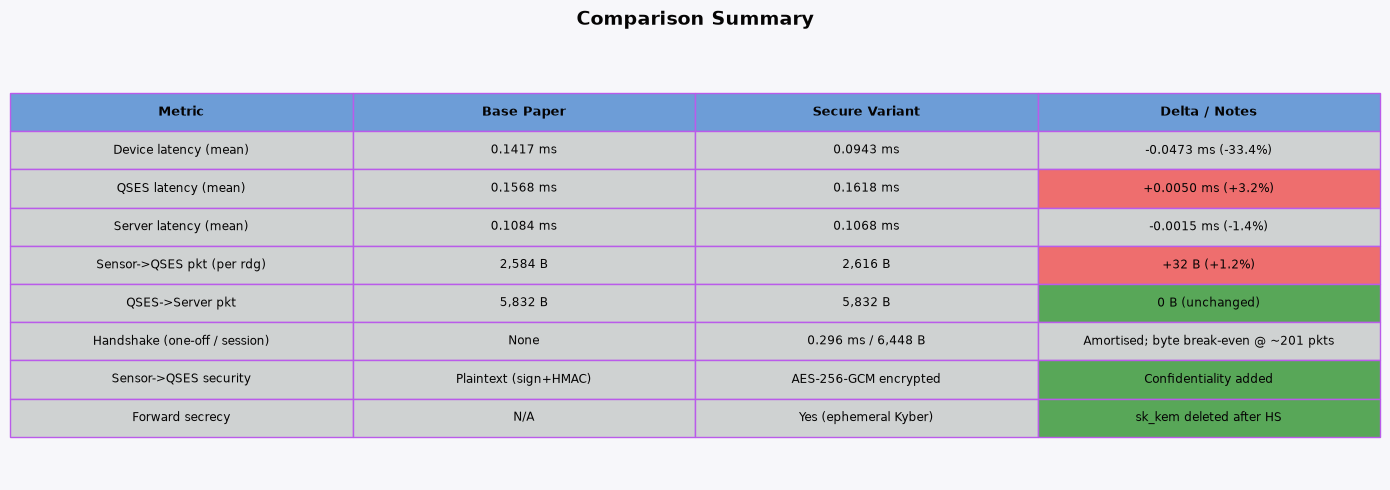

In [86]:
fig, ax = plt.subplots(figsize=(14, 5))
fig.patch.set_facecolor(DARK_BG); ax.set_facecolor(DARK_BG); ax.axis('off')

def dfmt(bm, sm):
    d = sm-bm; p = (sm/bm-1)*100 if bm > 0 else 0
    return f'{d:+.4f} ms ({p:+.1f}%)'

rows = [
    ['Device latency (mean)', f"{base_device['mean']:.4f} ms",
     f"{secure_device['mean']:.4f} ms", dfmt(base_device['mean'], secure_device['mean'])],
    ['QSES latency (mean)',   f"{base_qses['mean']:.4f} ms",
     f"{secure_qses['mean']:.4f} ms",   dfmt(base_qses['mean'],   secure_qses['mean'])],
    ['Server latency (mean)', f"{base_server['mean']:.4f} ms",
     f"{secure_server['mean']:.4f} ms", dfmt(base_server['mean'], secure_server['mean'])],
    ['Sensor->QSES pkt (per rdg)', f'{base_link_size:,} B', f'{secure_link_size:,} B',
     f'+{link_overhead} B (+{link_overhead/base_link_size*100:.1f}%)'],
    ['QSES->Server pkt', f'{edge_size:,} B', f'{edge_size:,} B', '0 B (unchanged)'],
    ['Handshake (one-off / session)', 'None',
     f"{hs_stats['mean']:.3f} ms / {hs_bytes:,} B",
     f'Amortised; byte break-even @ ~{hs_bytes//link_overhead} pkts'],
    ['Sensor->QSES security', 'Plaintext (sign+HMAC)',
     'AES-256-GCM encrypted', 'Confidentiality added'],
    ['Forward secrecy', 'N/A', 'Yes (ephemeral Kyber)', 'sk_kem deleted after HS'],
]
col_labels = ['Metric', 'Base Paper', 'Secure Variant', 'Delta / Notes']
t = ax.table(cellText=rows, colLabels=col_labels, cellLoc='center', loc='center')
t.auto_set_font_size(False); t.set_fontsize(8.5); t.scale(1, 2.05)
for (r, c), cell in t.get_celld().items():
    cell.set_facecolor(CARD_BG if r > 0 else "#6D9DD7")
    cell.set_edgecolor(GRID_CLR)
    cell.set_text_props(color=TEXT_CLR, fontsize=8.5)
    if r == 0: cell.set_text_props(fontweight='bold', fontsize=9.5)
    if r > 0 and c == 3:
        txt = rows[r-1][3]
        if '+' in txt and not any(x in txt for x in ['unchanged','Amort','added','deleted']):
            cell.set_facecolor("#EE6E6E")
        elif any(x in txt for x in ['unchanged','0 B','added','deleted']):
            cell.set_facecolor("#58A758")
ax.set_title('Comparison Summary', fontsize=14, fontweight='bold', color=TEXT_CLR, pad=18)
plt.tight_layout(); plt.show()


## Chart 8 — Latency Distribution (Violin Plots)

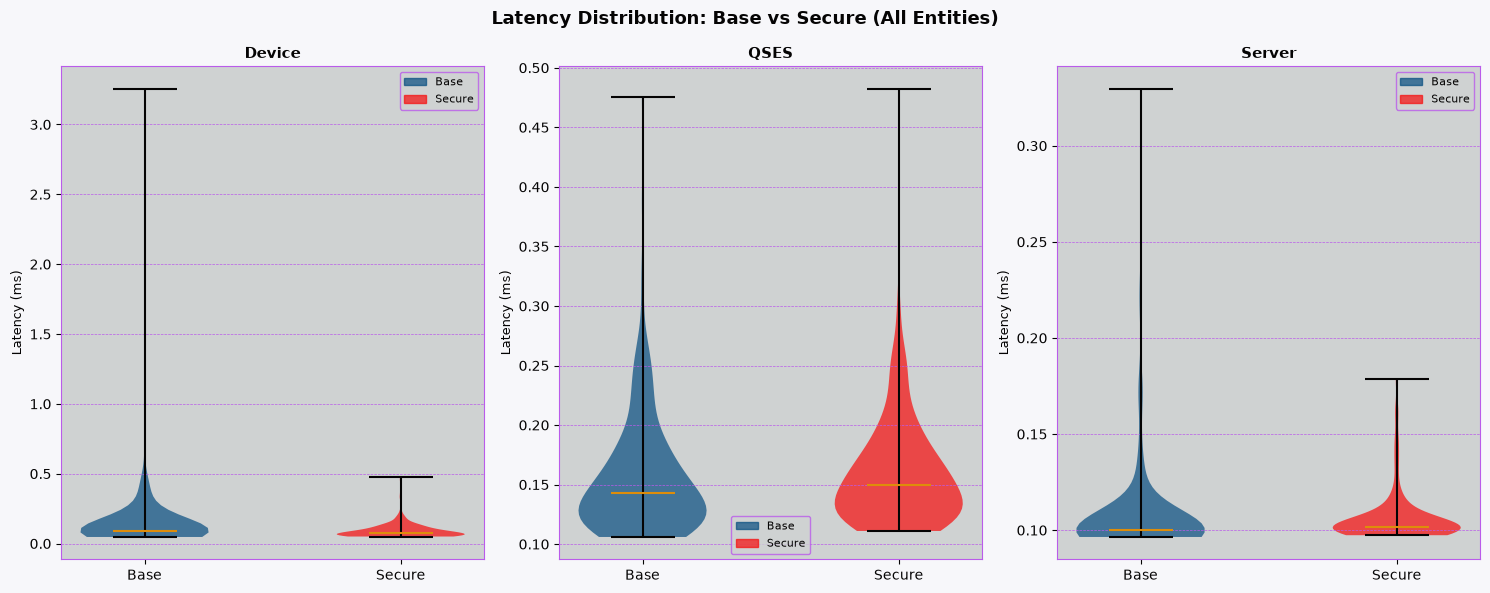

In [84]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('Latency Distribution: Base vs Secure (All Entities)',
             fontsize=13, fontweight='bold', color=TEXT_CLR)

pairs = [('Device', device_times_b, device_times_s),
         ('QSES',   qses_times_b,   qses_times_s),
         ('Server', server_times_b, server_times_s)]

for ax, (name, bs, ss) in zip(axes, pairs):
    vp = ax.violinplot([bs, ss], positions=[0, 1], showmedians=True, showextrema=True)
    for patch, col in zip(vp['bodies'], [C_BASE, C_SECURE]):
        patch.set_facecolor(col); patch.set_alpha(0.7)
    vp['cmedians'].set_color(C_ACCENT)
    for k in ('cbars','cmins','cmaxes'): vp[k].set_color(TEXT_CLR)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Base', 'Secure'], fontsize=10)
    ax.set_ylabel('Latency (ms)', fontsize=9)
    ax.set_title(name, fontsize=11, fontweight='bold', color=TEXT_CLR)
    ax.grid(axis='y')
    ax.legend(handles=[mpatches.Patch(color=C_BASE,   alpha=0.7, label='Base'),
                       mpatches.Patch(color=C_SECURE, alpha=0.7, label='Secure')], fontsize=8)

plt.tight_layout(); plt.show()


## Conclusion

### Is the overhead worth it?

| Dimension | Verdict |
|---|---|
| **Latency** | Tiny — AES-GCM adds < 5% per reading at Device and QSES; Server is unchanged |
| **Bytes (per reading)** | +32 B (+1.2%) on Sensor→QSES; QSES→Server is 0 B extra |
| **Session setup cost** | ~0.27 ms + 6 448 B — negligible vs any real IoMT interval (≥ 1 s) |
| **Security gained** | Full confidentiality on the previously plaintext Sensor→QSES hop |
| **Forward secrecy** | Yes — ephemeral Kyber key deleted; a compromised QSES cannot decrypt past sessions |
| **End-to-end auth** | Unchanged — ML-DSA device signature + HMAC still verified at the server |

### Break-even
- **Bytes**: the handshake (6 448 B) is amortised after ~202 readings (+32 B each)
- **Time**: the handshake (~0.27 ms) is amortised after just a few readings vs the tiny AES-GCM floor (~0.004 ms)

> For any session longer than a single reading — which is every real-world IoMT scenario —
> the overhead per reading is **negligible** and the security benefit is **substantial**.
